# 02 · Hierarchy and time-irreversibility

Visualises `src/hierarchy` output (run `python -m src.hierarchy.run`). Model-based FDT deviation (Acero-Pousa et al.
2025) and model-free pairwise time-irreversibility, across HC / AP / NAP, per network, and vs symptoms.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.core import paths
from src.core.data import GROUPS, load_data, load_model_results, load_features

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"HC": "#2a9d8f", "AP": "#e76f51", "NAP": "#e9c46a"}

In [2]:
D = paths.DERIVED / "hierarchy"
S = pd.read_csv(D / "subject_measures.csv")
G = pd.read_csv(D / "group_tests.csv")
GN = pd.read_csv(D / "group_tests_networks.csv")
C = pd.read_csv(D / "symptom_correlations.csv")
A = pd.read_csv(D / "irreversibility_adjusted.csv")
display(G.round(4))

,measure,mean_HC,mean_AP,mean_NAP,F,p_perm,g_AP_vs_HC,g_NAP_vs_HC,g_NAP_vs_AP,q_FDR
0,Dhat,51.4290,40.5795,42.5989,1.3053,0.2715,-0.2970,-0.2673,0.0627,0.2987
1,sd_P,135.6830,186.6520,105.2590,0.7656,0.4961,0.1561,-0.1216,-0.2612,0.4961
2,GEC_asym,0.0317,0.0250,0.0234,9.1836,0.0002,-0.5060,-0.7670,-0.1925,0.0003
3,GEC_strength,1.6267,1.4400,1.4931,1.6848,0.1886,-0.3898,-0.2725,0.1160,0.2305
4,FC_mean,0.4093,0.3542,0.3710,2.0543,0.1304,-0.4224,-0.3001,0.1396,0.1793
5,irr_lag1,0.0027,0.0016,0.0014,12.9840,0.0002,-0.5955,-0.8874,-0.2075,0.0003
6,irr_lag2,0.0103,0.0059,0.0052,13.0169,0.0002,-0.5999,-0.8867,-0.2001,0.0003
7,irr_lag3,0.0210,0.0121,0.0108,13.0510,0.0002,-0.6070,-0.8848,-0.1869,0.0003
8,irr_hier_lag1,0.0015,0.0009,0.0008,11.5662,0.0002,-0.5096,-0.8830,-0.2817,0.0003
9,irr_hier_lag2,0.0058,0.0035,0.0029,11.6528,0.0002,-0.5167,-0.8833,-0.2737,0.0003


## Group differences

/tmp/ipykernel_434974/2102931846.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_434974/2102931846.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_434974/2102931846.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_434974/2102931846.py:4: FutureWarning

/tmp/ipykernel_434974/2102931846.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_434974/2102931846.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)


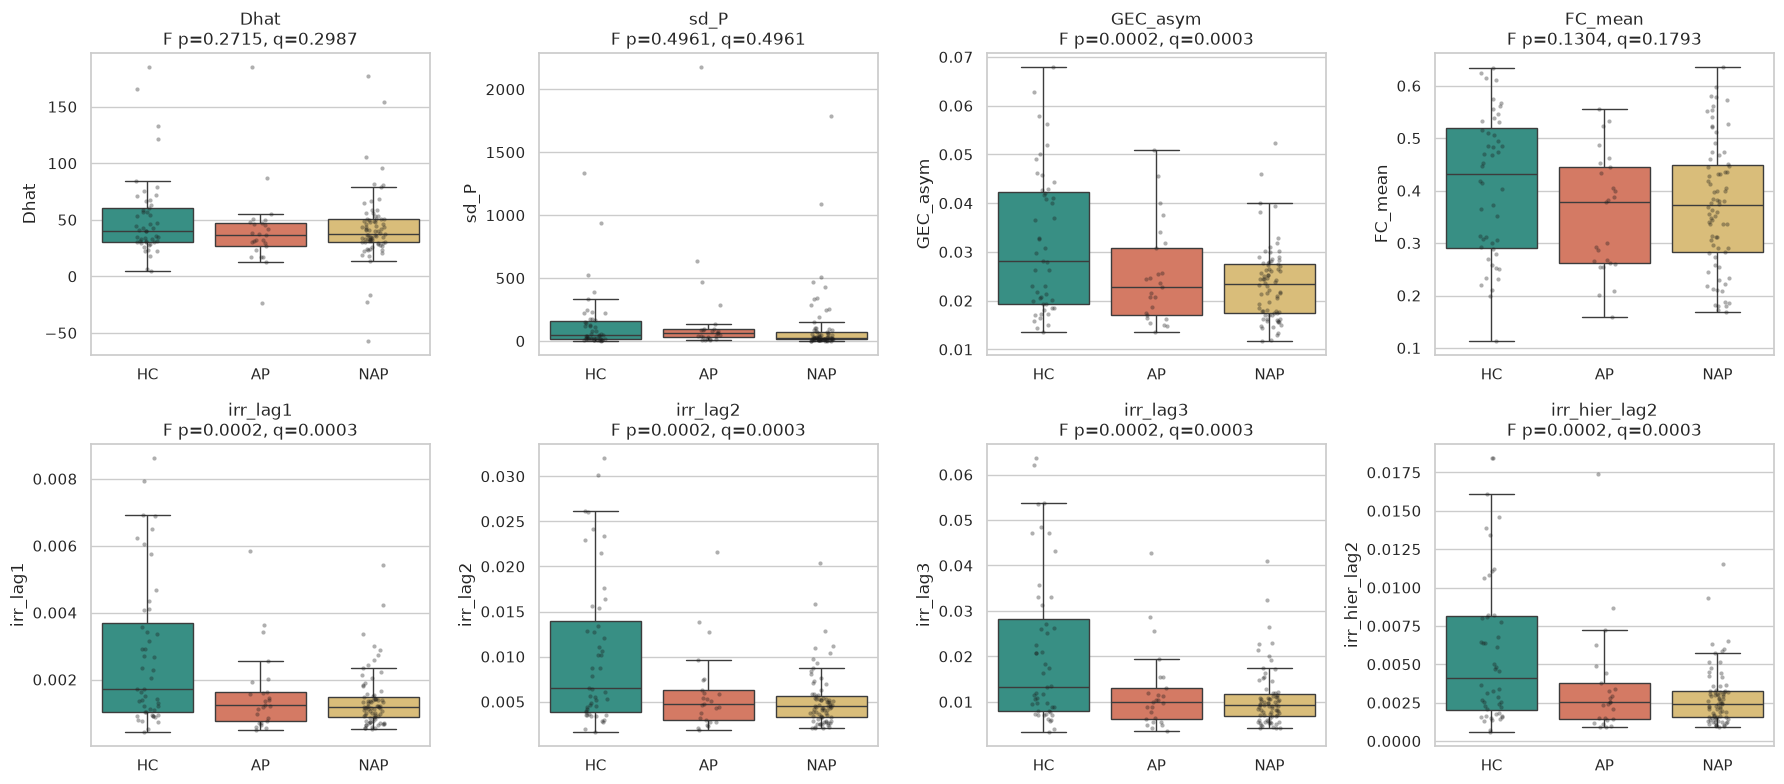

In [3]:
show = ["Dhat", "sd_P", "GEC_asym", "FC_mean", "irr_lag1", "irr_lag2", "irr_lag3", "irr_hier_lag2"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, m in zip(axes.ravel(), show):
    sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=S, x="group", y=m, order=GROUPS, color="k", alpha=.35, size=3, ax=ax)
    r = G.set_index("measure").loc[m]
    ax.set_title(f"{m}\nF p={r.p_perm:.4f}, q={r.q_FDR:.4f}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Effect sizes per Yeo network

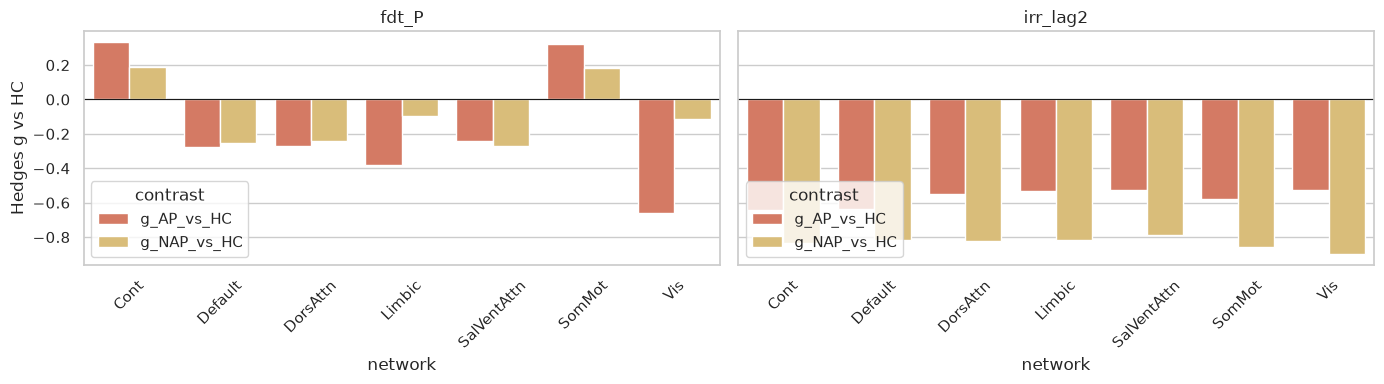

,measure,network,mean_HC,mean_AP,mean_NAP,F,p_perm,g_AP_vs_HC,g_NAP_vs_HC,q_FDR
0,fdt_P,Cont,33.4646,43.6627,38.7888,1.1591,0.3073,0.3344,0.1878,0.3310
1,fdt_P,Default,56.0920,33.4567,35.7038,1.3093,0.2944,-0.2761,-0.2541,0.3310
2,fdt_P,DorsAttn,50.8771,33.4925,38.6360,1.4772,0.2139,-0.2691,-0.2395,0.2722
3,fdt_P,Limbic,40.0996,8.3645,34.3001,2.5570,0.0835,-0.3835,-0.0986,0.1461
4,fdt_P,SalVentAttn,55.0548,29.5263,36.2268,1.0270,0.3983,-0.2417,-0.2688,0.3983
5,fdt_P,SomMot,44.1338,102.9602,55.0723,1.6568,0.1744,0.3231,0.1858,0.2442
6,fdt_P,Vis,65.8507,20.4355,55.4102,2.2351,0.1024,-0.6579,-0.1130,0.1594
7,irr_lag2,Cont,0.0095,0.0051,0.0048,12.4077,0.0005,-0.6397,-0.8363,0.0010
8,irr_lag2,Default,0.0083,0.0048,0.0047,12.0151,0.0005,-0.6363,-0.8196,0.0010
9,irr_lag2,DorsAttn,0.0091,0.0055,0.0047,11.4069,0.0005,-0.5509,-0.8253,0.0010


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, kind in zip(axes, ("fdt_P", "irr_lag2")):
    d = GN[GN.measure == kind].melt(id_vars="network", value_vars=["g_AP_vs_HC", "g_NAP_vs_HC"], var_name="contrast", value_name="g")
    sns.barplot(data=d, x="network", y="g", hue="contrast", ax=ax, palette=[PALETTE["AP"], PALETTE["NAP"]])
    ax.axhline(0, color="k", lw=.8); ax.set_title(kind); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Hedges g vs HC")
plt.tight_layout(); plt.show()
display(GN.round(4))

## Nodal irreversibility (lag 2): NAP − HC on the brain

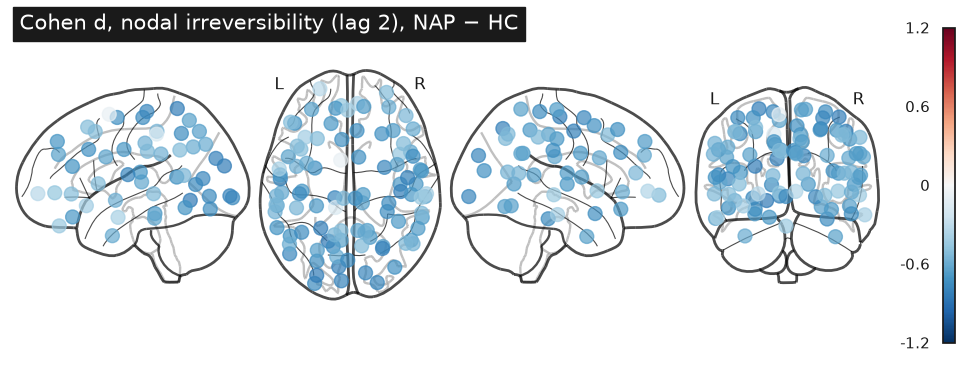

In [5]:
from nilearn import plotting
feats = load_features()
atlas = load_model_results()["atlas"]
nodal = {g: np.array([feats[g][k]["irr_nodal"][2] for k in feats[g]]) for g in GROUPS}
pooled_sd = np.sqrt((nodal["HC"].var(0, ddof=1) + nodal["NAP"].var(0, ddof=1)) / 2)
d = (nodal["NAP"].mean(0) - nodal["HC"].mean(0)) / pooled_sd
plotting.plot_markers(d, atlas["coords"], node_cmap="RdBu_r", node_vmin=-1.2, node_vmax=1.2,
                      title="Cohen d, nodal irreversibility (lag 2), NAP − HC", display_mode="lzry")
plt.show()

## Is it just weaker FC? Irreversibility vs mean FC and vs model asymmetry

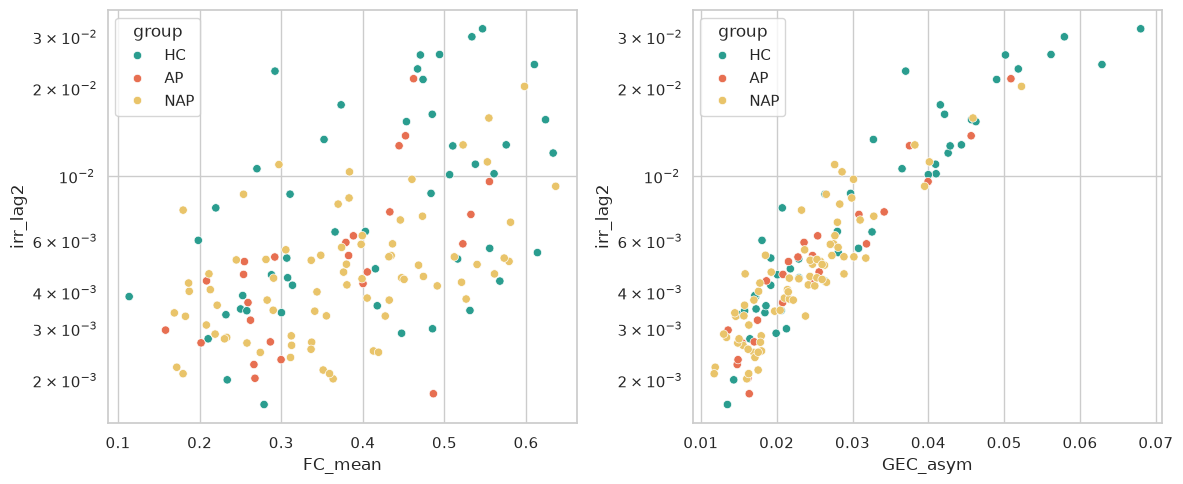

Group effect after adjusting log-irreversibility for mean FC and lag-1 autocorrelation:


,lag,F_adj,p_perm,g_AP_vs_HC_adj,g_NAP_vs_HC_adj,g_NAP_vs_AP_adj
0,1,6.3639,0.0018,-0.4936,-0.6470,-0.0695
1,2,6.3424,0.0018,-0.4943,-0.6458,-0.0666
2,3,6.2976,0.0018,-0.4955,-0.6431,-0.0612


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=S, x="FC_mean", y="irr_lag2", hue="group", palette=PALETTE, ax=axes[0])
sns.scatterplot(data=S, x="GEC_asym", y="irr_lag2", hue="group", palette=PALETTE, ax=axes[1])
for ax in axes: ax.set_yscale("log")
plt.tight_layout(); plt.show()
print("Group effect after adjusting log-irreversibility for mean FC and lag-1 autocorrelation:")
display(A.round(4))

## Symptom correlations (patients, partial Spearman controlling AP/NAP)

,target,measure,rho_partial,p_perm,n,q_FDR
11,YMRS,Dhat,0.1975,0.0546,98,0.6005
0,PANSS,Dhat,-0.1647,0.1162,92,0.8668
1,PANSS,sd_P,-0.1002,0.3493,92,0.8668
15,YMRS,FC_mean,0.0728,0.4719,98,0.9734
5,PANSS,irr_lag1,-0.0525,0.6121,92,0.8668
6,PANSS,irr_lag2,-0.0496,0.6341,92,0.8668
7,PANSS,irr_lag3,-0.0463,0.6575,92,0.8668
14,YMRS,GEC_strength,0.0460,0.6593,98,0.9734
3,PANSS,GEC_strength,-0.0426,0.6939,92,0.8668
13,YMRS,GEC_asym,0.0392,0.7115,98,0.9734


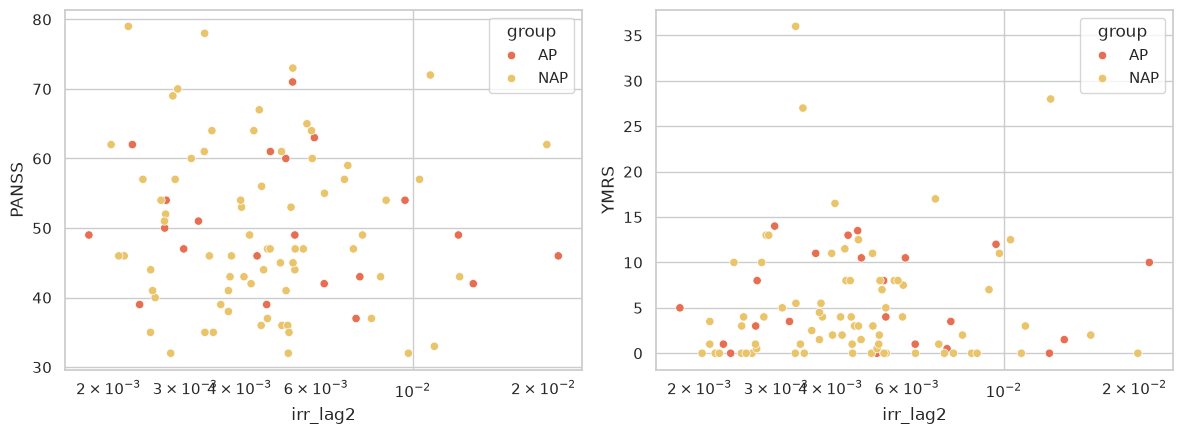

In [7]:
display(C.sort_values("p_perm").round(4))
P = S[S.group != "HC"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t in zip(axes, ("PANSS", "YMRS")):
    sns.scatterplot(data=P, x="irr_lag2", y=t, hue="group", palette=PALETTE, ax=ax); ax.set_xscale("log")
plt.tight_layout(); plt.show()